# 07 - Poisson likelihood versus chi-square at low counts

The pipeline minimises the **Poisson deviance** over every pixel, zeros included. Most
published eVDF fits minimise a **chi-square over the detected pixels** (counts > 0),
usually in log space, where a zero PSD has no logarithm.

This notebook compares the two on real data and on synthetic data with a known truth.
Model, stages, initial guesses and parameter ranges are identical, so the objective is
the only difference (`fitEpoch(..., objective='poisson' | 'chi2')`).

**Runtime:** about 4 minutes (two fits of one epoch, a chi-square batch run of the 30
epochs, 24 synthetic fits on 4 workers).

In [1]:
import os
import sys
from pathlib import Path

# Single-threaded linear algebra, set before numpy is imported: the fits are
# many small least-squares problems, and this makes the numbers in this
# notebook identical to those of the batch runner (which spawns 1-thread workers).
for name in ('OMP_NUM_THREADS', 'OPENBLAS_NUM_THREADS', 'MKL_NUM_THREADS', 'NUMEXPR_NUM_THREADS'):
    os.environ.setdefault(name, '1')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Repository root = the first parent directory that contains src/evdf_poisson
REPO_ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'src' / 'evdf_poisson').is_dir())
sys.path.insert(0, str(REPO_ROOT / 'src'))

CALIBRATION_DIR = REPO_ROOT / 'examples' / 'example_data'          # EAS geometric factors, head geometry, scpot table
EXAMPLE_DIR = CALIBRATION_DIR / 'poisson_2023-04-04'                # the 30-epoch example subset
EXAMPLE_FILE = EXAMPLE_DIR / 'VDF_eas_forFitting_20230404005008_20230404011908_1min.h5'
RESULTS_DIR = REPO_ROOT / 'results' / 'fitting' / 'example_run_poisson'       # reference fit of the subset
DAYS_DIR = REPO_ROOT / 'results' / 'fitting' / 'example_days_2023-04-04_05'   # reference fit of the two full days
GEOMETRY_FILE = CALIBRATION_DIR / 'eas_head_geometry.npz'
print('repository:', REPO_ROOT)

repository: /disk/plasma/xw2/SO-EAS-eVDF_Fitting


## 1. The same epoch, two objectives

Both fits get identical inputs. `chi2` minimises
$\sum_{C_i > 0} [\log_{10} f_\text{model}(v_i) - \log_{10} f_i]^2$;
`poisson` minimises the deviance of notebook 05 over all valid pixels.

/disk/anaconda/xw2/miniconda3/envs/SunSolarWind/lib/python3.10/site-packages/uncertainties/core.py:1024: UserWarning: Using UFloat objects with std_dev==0 may give unexpected results.
  warn("Using UFloat objects with std_dev==0 may give unexpected results.")


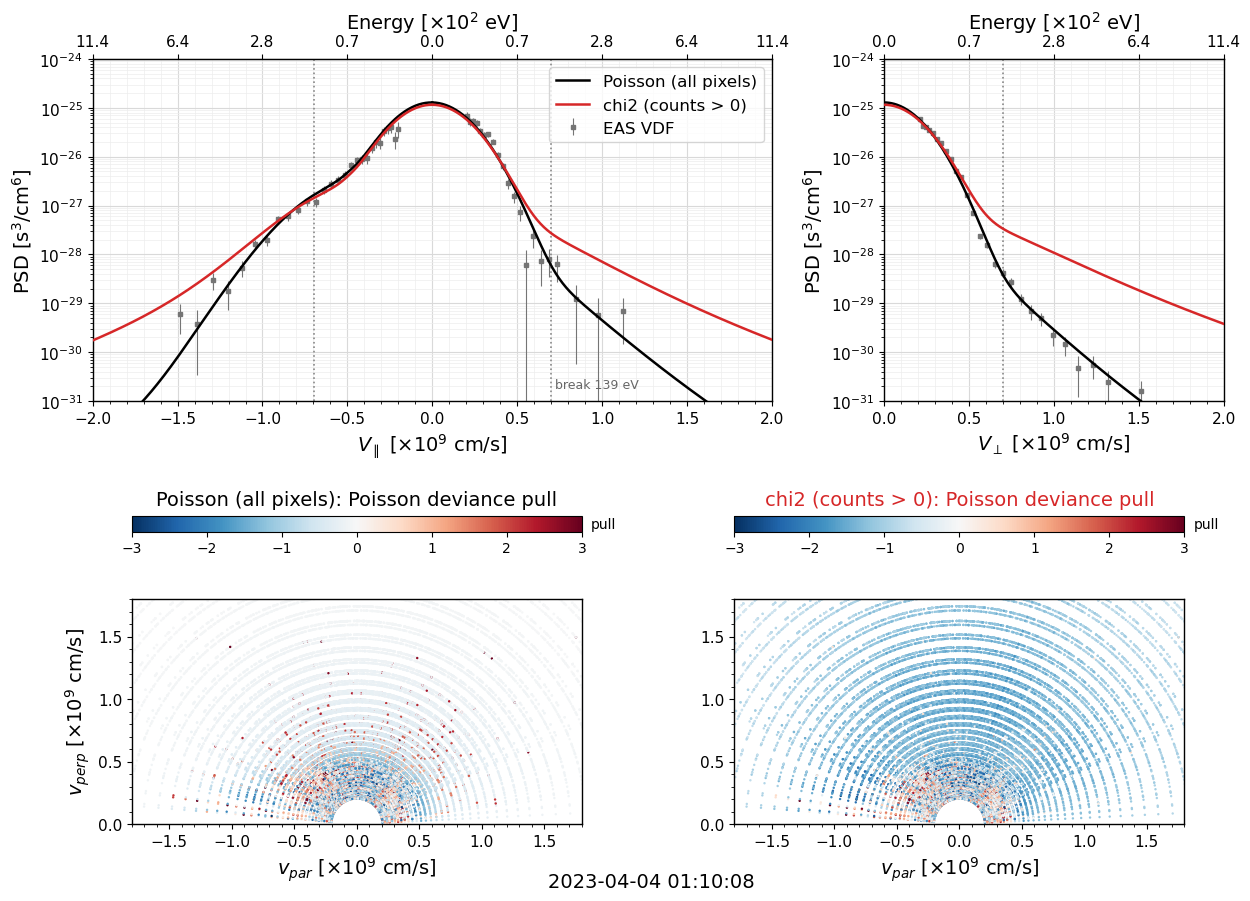

In [2]:
from evdf_poisson import loadEpoch, detectStrahlFromPad, seedFromData, fitEpoch
from evdf_poisson import poissonDeviancePerDof, reducedChiSquare, componentMomentsFromParams
from evdf_poisson.plotting import plotFitComparison

EPOCH = 20
grid, psd, counts, epochNs, scDensity = loadEpoch(EXAMPLE_FILE, EPOCH)
epochTime = pd.Timestamp(int(epochNs))
breakTable = pd.read_csv(EXAMPLE_DIR / (EXAMPLE_FILE.stem + '_two_population_crossing.csv'))
breakEnergyEv = float(breakTable.loc[EPOCH, 'break_E_eV'])
detection = detectStrahlFromPad(EXAMPLE_FILE, EPOCH, breakEnergyEv)
seeds = seedFromData(psd, counts, grid, strahlDetection=detection, scDensity=scDensity, breakEnergyEv=breakEnergyEv)

fits = {}
for objective, label in (('poisson', 'Poisson (all pixels)'), ('chi2', 'chi2 (counts > 0)')):
    params, modelPsd, diagnostics = fitEpoch(psd, counts, grid, seeds, objective=objective)
    fits[label] = {'params': params,
                   'deviance_per_dof': poissonDeviancePerDof(modelPsd, counts, grid, diagnostics['free_params']),
                   'red_chi2': reducedChiSquare(modelPsd, psd, counts, grid, diagnostics['free_params'])}

fig = plotFitComparison(grid, psd, counts, {label: fit['params'] for label, fit in fits.items()},
                        breakEnergyEv=breakEnergyEv, timeLabel=str(epochTime))

In [3]:
comparison = pd.DataFrame({label: {**componentMomentsFromParams(fit['params']),
                                   'deviance_per_dof': fit['deviance_per_dof'], 'red_chi2': fit['red_chi2']}
                           for label, fit in fits.items()})
comparison['chi2 / Poisson'] = comparison.iloc[:, 1] / comparison.iloc[:, 0]
comparison.map(lambda value: f'{value:.4g}')

,Poisson (all pixels),chi2 (counts > 0),chi2 / Poisson
n_c,9.361,8.876,0.9481
u_par_c,-4.723e+06,-2.04e+06,0.4319
T_par_c_eV,16.69,16.75,1.004
T_perp_c_eV,15.36,16.33,1.063
n_h,0.1855,1.774,9.562
u_par_h,4.631e+06,2.727e+07,5.889
T_par_h_eV,66.6,185,2.778
T_perp_h_eV,58.74,245.6,4.181
kappa_h,5.064,2.7,0.5331
n_b,0.1342,0.1836,1.368


What to look at:

- **The tails.** Above ~300 eV the chi-square total (red) runs above the channel means
  in every cut, by up to an order of magnitude at 1 keV. Its pull map is blue at high
  energy: it predicts counts that were not seen. The Poisson total (black) follows the
  means.
- **The halo.** Chi-square makes it three times hotter and ten times denser, with
  $\kappa_h$ halved: the only way to pass through the detected pixels of a faint tail.
- **The goodness of fit.** Chi-square has the *better* reduced chi-square (the quantity
  it minimised, on the pixels it looked at) and the *worse* deviance. Reduced
  chi-square on detected pixels cannot see the problem.

## 2. All thirty epochs

Is this systematic? The ratio chi-square / Poisson of every parameter, epoch by epoch
(`runFiles(..., objective='chi2')`):

2026-10-05 19:01:55  1 files, 4 workers, objective=chi2, halo drift free -> /disk/plasma/xw2/SO-EAS-eVDF_Fitting/results/fitting/example_run_chi2


2026-10-05 19:01:55  [1/1] VDF_eas_forFitting_20230404005008_20230404011908_1min.h5 already complete, skipping


2026-10-05 19:01:55  merged 1 file CSVs -> summary.csv (30 rows)


,median ratio chi2/Poisson,Poisson median,chi2 median
n_c,0.938,9.993,9.436
T_par_c_eV,1.007,17.415,17.470
n_h,11.090,0.173,1.857
T_par_h_eV,2.676,71.324,195.737
kappa_h,0.495,5.632,2.799
n_b,1.195,0.124,0.138
T_par_b_eV,1.611,32.044,51.735
T_perp_b_eV,2.613,12.229,31.254
kappa_b,0.225,18.894,3.191


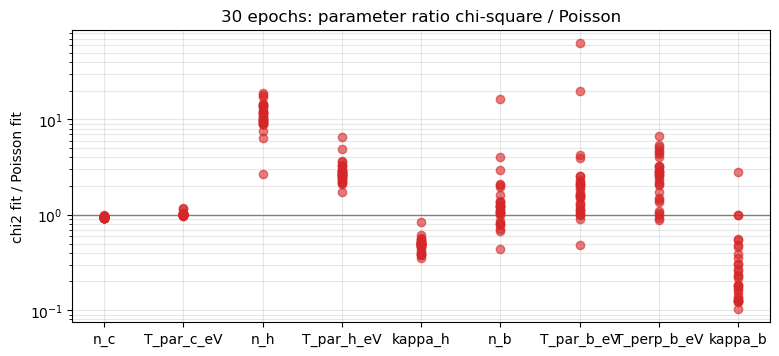

In [4]:
from evdf_poisson.runner import runFiles

CHI2_DIR = REPO_ROOT / 'results' / 'fitting' / 'example_run_chi2'
poissonSummary = pd.read_csv(RESULTS_DIR / 'summary.csv').set_index('epoch_index')
chi2Summary = runFiles(EXAMPLE_DIR, CHI2_DIR, workers=4, objective='chi2').set_index('epoch_index')

PARAMETERS = ['n_c', 'T_par_c_eV', 'n_h', 'T_par_h_eV', 'kappa_h', 'n_b', 'T_par_b_eV', 'T_perp_b_eV', 'kappa_b']
ratio = chi2Summary[PARAMETERS] / poissonSummary[PARAMETERS]
fig, ax = plt.subplots(figsize=(9, 3.8))
ax.axhline(1, color='0.5', linewidth=1)
for column in PARAMETERS:
    ax.plot([column] * len(ratio), ratio[column], 'o', color='#d62728', alpha=0.6)
ax.set_yscale('log'); ax.set_ylabel('chi2 fit / Poisson fit'); ax.grid(alpha=0.3, which='both')
ax.set_title('30 epochs: parameter ratio chi-square / Poisson')
pd.DataFrame({'median ratio chi2/Poisson': ratio.median(),
              'Poisson median': poissonSummary[PARAMETERS].median(),
              'chi2 median': chi2Summary[PARAMETERS].median()}).round(3)

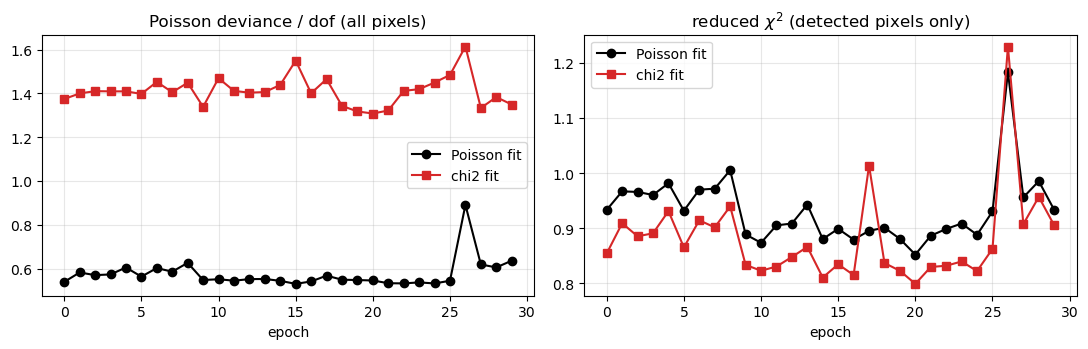

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
for ax, column, title in ((axes[0], 'deviance_per_dof', 'Poisson deviance / dof (all pixels)'),
                          (axes[1], 'red_chi2', r'reduced $\chi^2$ (detected pixels only)')):
    ax.plot(poissonSummary.index, poissonSummary[column], 'o-', color='black', label='Poisson fit')
    ax.plot(chi2Summary.index, chi2Summary[column], 's-', color='#d62728', label='chi2 fit')
    ax.set_title(title); ax.set_xlabel('epoch'); ax.grid(alpha=0.3); ax.legend()
fig.tight_layout()

On every epoch chi-square wins on its own metric and loses on the deviance. The halo
changes *qualitatively*: ten times the density, three times the temperature, $\kappa_h$
halved. The strahl comes out 1.5-2 times hotter with a much harder tail
($\kappa_b$ ~3 instead of ~20).

## 3. Known truth: synthetic data at decreasing count level

Real data have no truth, so we make some:

1. take the Poisson fit of this epoch as the truth;
2. evaluate it on the real instrument grid and convert to expected counts with the real
   one-count levels;
3. draw Poisson counts and fit them with both objectives (always the same draw for
   both).

The **brightness** factor scales the expected counts, as a shorter accumulation time
or a smaller geometric factor would: 1 = as observed, 0.3 and 0.1 = fainter. The truth
model is the fit model itself, so any deviation is caused by the objective alone.

In [6]:
from evdf_poisson.synthetic import runSyntheticBenchmark

truthParams = fits['Poisson (all pixels)']['params']
benchmark = runSyntheticBenchmark(EXAMPLE_FILE, EPOCH, truthParams, detection, breakEnergyEv,
                                  brightnessLevels=(1.0, 0.3, 0.1), numRealisations=4, workers=4)
benchmark.groupby(['brightness', 'objective'])[['total_counts', 'zero_count_fraction', 'deviance_per_dof', 'red_chi2']].mean().round(3)

/disk/anaconda/xw2/miniconda3/envs/SunSolarWind/lib/python3.10/site-packages/uncertainties/core.py:1024: UserWarning: Using UFloat objects with std_dev==0 may give unexpected results.
  warn("Using UFloat objects with std_dev==0 may give unexpected results.")


/disk/anaconda/xw2/miniconda3/envs/SunSolarWind/lib/python3.10/site-packages/uncertainties/core.py:1024: UserWarning: Using UFloat objects with std_dev==0 may give unexpected results.
  warn("Using UFloat objects with std_dev==0 may give unexpected results.")
/disk/anaconda/xw2/miniconda3/envs/SunSolarWind/lib/python3.10/site-packages/uncertainties/core.py:1024: UserWarning: Using UFloat objects with std_dev==0 may give unexpected results.
  warn("Using UFloat objects with std_dev==0 may give unexpected results.")
/disk/anaconda/xw2/miniconda3/envs/SunSolarWind/lib/python3.10/site-packages/uncertainties/core.py:1024: UserWarning: Using UFloat objects with std_dev==0 may give unexpected results.
  warn("Using UFloat objects with std_dev==0 may give unexpected results.")


total_counts  zero_count_fraction  deviance_per_dof  \
brightness objective                                                        
0.1        chi2            3007.25                0.939             0.606   
           poisson         3007.25                0.939             0.241   
0.3        chi2            9043.50                0.849             0.875   
           poisson         9043.50                0.849             0.381   
1.0        chi2           29761.75                0.709             1.023   
           poisson        29761.75                0.709             0.479   

                      red_chi2  
brightness objective            
0.1        chi2          0.336  
           poisson       0.723  
0.3        chi2          0.273  
           poisson       0.465  
1.0        chi2          0.640  
           poisson       0.709

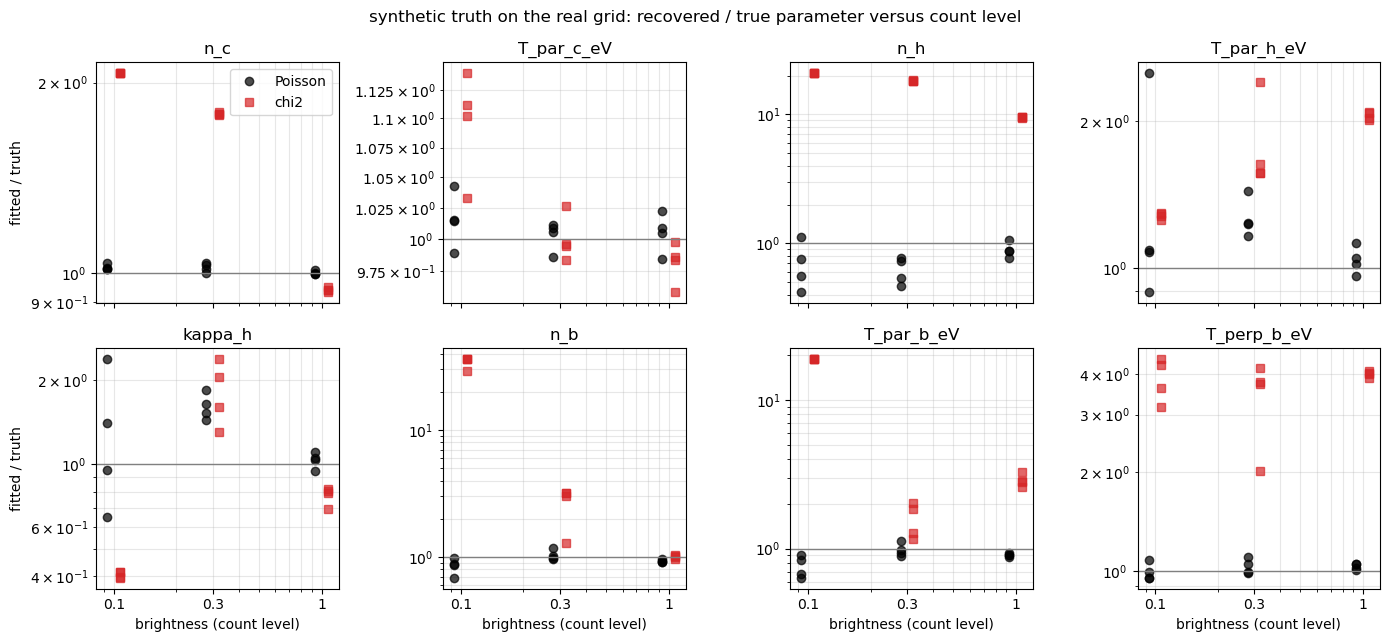

In [7]:
PARAMETERS = ['n_c', 'T_par_c_eV', 'n_h', 'T_par_h_eV', 'kappa_h', 'n_b', 'T_par_b_eV', 'T_perp_b_eV']
STYLE = {'poisson': ('black', 'o', 'Poisson'), 'chi2': ('#d62728', 's', 'chi2')}
fig, axes = plt.subplots(2, 4, figsize=(14, 6.5), sharex=True)
for ax, name in zip(axes.ravel(), PARAMETERS):
    for objective, (color, marker, label) in STYLE.items():
        rows = benchmark[benchmark['objective'] == objective]
        jitter = (0.93 if objective == 'poisson' else 1.07)
        ax.plot(rows['brightness'] * jitter, rows[f'fit_{name}'] / rows[f'truth_{name}'],
                marker, color=color, alpha=0.7, linestyle='none', label=label)
    ax.axhline(1, color='0.5', linewidth=1)
    ax.set_xscale('log'); ax.set_yscale('log'); ax.set_title(name); ax.grid(alpha=0.3, which='both')
    ax.set_xticks([1.0, 0.3, 0.1]); ax.set_xticklabels(['1', '0.3', '0.1'])
for ax in axes[1]: ax.set_xlabel('brightness (count level)')
for ax in axes[:, 0]: ax.set_ylabel('fitted / truth')
axes[0, 0].legend()
fig.suptitle('synthetic truth on the real grid: recovered / true parameter versus count level')
fig.tight_layout()

Reading the panels:

- **Core:** recovered by both objectives at every count level (it lives where counts
  are high).
- **Halo and strahl, Poisson:** recovered at all count levels, with a scatter that
  grows as the counts drop.
- **Halo and strahl, chi-square:** biased already at the observed brightness, and more
  so as the counts drop: halo too hot and too dense, $\kappa_h$ too low, strahl too
  wide. Its own reduced chi-square stays near or below 1 throughout.

## 4. Why: the survivor bias of detected pixels

A pixel that expects $\mu$ counts registers zero with probability $e^{-\mu}$. Averaging
only the pixels with $C > 0$ estimates not $\mu$ but

$$ \mathrm{E}[C \mid C > 0] = \frac{\mu}{1 - e^{-\mu}} . $$

For $\mu = 0.1$ that is 1.05, ten times the truth. A fit that sees only the detected
pixels is pulled towards this censored mean wherever the expected counts are below
about one, which in EAS data is the whole suprathermal range. The Poisson likelihood
keeps the $e^{-\mu}$ of the empty pixels and is unbiased at any count level (Cash 1979;
Humphrey et al. 2009; Nicolaou et al. 2024).

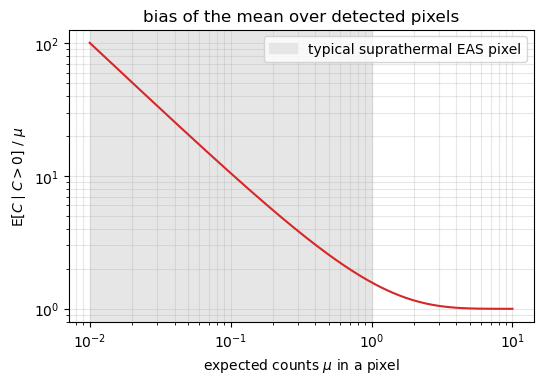

In [8]:
expectedCounts = np.logspace(-2, 1, 200)
survivorMean = expectedCounts / (1 - np.exp(-expectedCounts))
fig, ax = plt.subplots(figsize=(6, 3.8))
ax.loglog(expectedCounts, survivorMean / expectedCounts, color='#d62728')
ax.set_xlabel(r'expected counts $\mu$ in a pixel'); ax.set_ylabel(r'E[$C \mid C>0$] / $\mu$')
ax.set_title('bias of the mean over detected pixels'); ax.grid(alpha=0.3, which='both')
ax.axvspan(0.01, 1, color='0.9', label='typical suprathermal EAS pixel'); ax.legend();

## 5. Conclusions

- Same model, stages and ranges: the objective alone changes the halo density by an
  order of magnitude, its temperature by a factor 3 and $\kappa_h$ from ~5.6 to ~2.8
  on this data.
- Reduced chi-square on detected pixels does not diagnose the problem; the Poisson
  deviance on all pixels does.
- On synthetic data with a known truth, the Poisson fit is unbiased down to a tenth of
  the observed count level. The chi-square fit is biased at every level, increasingly
  so as counts drop.
- This is why the pipeline uses the Poisson deviance in every stage and reports
  `deviance_per_dof` as its goodness of fit.